<a href="https://colab.research.google.com/github/San-Maansson/Stock_Analysis/blob/main/Equity_Risk_and_Performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pyfolio_reloaded

In [10]:
import pyfolio as pf
import yfinance as yf

/usr/local/lib/python3.12/dist-packages/pyfolio/pos.py:25: UserWarning: Module "zipline.assets" not found; multipliers will not be applied to position notionals.
  warnings.warn(


In [22]:
bench = yf.Ticker('SPY').history('max')

In [23]:
bench

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Capital Gains
Date,,,,,,,,
1993-01-29 00:00:00-05:00,24.192571,24.192571,24.072210,24.175377,1003200,0.0,0.0,0.0
1993-02-01 00:00:00-05:00,24.192578,24.347328,24.192578,24.347328,480500,0.0,0.0,0.0
1993-02-02 00:00:00-05:00,24.330137,24.416109,24.278553,24.398914,201300,0.0,0.0,0.0
1993-02-03 00:00:00-05:00,24.433289,24.674011,24.416094,24.656816,529400,0.0,0.0,0.0
1993-02-04 00:00:00-05:00,24.742796,24.811574,24.467685,24.759991,531500,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
2026-04-01 00:00:00-04:00,653.900024,658.520020,653.000000,655.239990,97841500,0.0,0.0,0.0
2026-04-02 00:00:00-04:00,646.419983,658.200012,645.109985,655.830017,68358700,0.0,0.0,0.0
2026-04-06 00:00:00-04:00,655.859985,659.719971,655.520020,658.929993,39105800,0.0,0.0,0.0


In [24]:
bench_returns = bench.Close.pct_change()

/tmp/ipykernel_2407/3729781627.py:1: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  bench_returns = bench.Close.pct_change()


In [25]:
bench_returns

,Close
Date,
1993-01-29 00:00:00-05:00,NaN
1993-02-01 00:00:00-05:00,0.007113
1993-02-02 00:00:00-05:00,0.002119
1993-02-03 00:00:00-05:00,0.010570
1993-02-04 00:00:00-05:00,0.004184
...,...
2026-04-01 00:00:00-04:00,0.007534
2026-04-02 00:00:00-04:00,0.000900
2026-04-06 00:00:00-04:00,0.004727


In [26]:
data = yf.Ticker('NVDA').history('max')

In [27]:
data

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
1999-01-22 00:00:00-05:00,0.040109,0.044765,0.035573,0.037603,2714688000,0.0,0.0
1999-01-25 00:00:00-05:00,0.040587,0.042019,0.037603,0.041542,510480000,0.0,0.0
1999-01-26 00:00:00-05:00,0.042019,0.042855,0.037722,0.038319,343200000,0.0,0.0
1999-01-27 00:00:00-05:00,0.038438,0.039393,0.036289,0.038200,244368000,0.0,0.0
1999-01-28 00:00:00-05:00,0.038200,0.038438,0.037841,0.038080,227520000,0.0,0.0
...,...,...,...,...,...,...,...
2026-04-01 00:00:00-04:00,176.000000,177.369995,174.750000,175.750000,168132000,0.0,0.0
2026-04-02 00:00:00-04:00,172.179993,177.490005,171.369995,177.389999,143143200,0.0,0.0
2026-04-06 00:00:00-04:00,177.160004,177.789993,175.759995,177.639999,107564300,0.0,0.0


In [28]:
returns = data.Close.pct_change()

/tmp/ipykernel_2407/3267454896.py:1: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = data.Close.pct_change()


In [30]:
returns

,Close
Date,
1999-01-22 00:00:00-05:00,NaN
1999-01-25 00:00:00-05:00,0.104764
1999-01-26 00:00:00-05:00,-0.077594
1999-01-27 00:00:00-05:00,-0.003110
1999-01-28 00:00:00-05:00,-0.003144
...,...
2026-04-01 00:00:00-04:00,0.007741
2026-04-02 00:00:00-04:00,0.009331
2026-04-06 00:00:00-04:00,0.001409


In [33]:
returns = returns.dropna()
bench_returns = bench_returns.dropna()

In [34]:
returns, bench_returns = returns.align(bench_returns, join = 'inner')

In [35]:
returns

,Close
Date,
1999-01-25 00:00:00-05:00,0.104764
1999-01-26 00:00:00-05:00,-0.077594
1999-01-27 00:00:00-05:00,-0.003110
1999-01-28 00:00:00-05:00,-0.003144
1999-01-29 00:00:00-05:00,-0.047019
...,...
2026-04-01 00:00:00-04:00,0.007741
2026-04-02 00:00:00-04:00,0.009331
2026-04-06 00:00:00-04:00,0.001409


In [36]:
bench_returns

,Close
Date,
1999-01-25 00:00:00-05:00,0.010198
1999-01-26 00:00:00-05:00,0.018173
1999-01-27 00:00:00-05:00,-0.011651
1999-01-28 00:00:00-05:00,0.016804
1999-01-29 00:00:00-05:00,0.007646
...,...
2026-04-01 00:00:00-04:00,0.007534
2026-04-02 00:00:00-04:00,0.000900
2026-04-06 00:00:00-04:00,0.004727


/usr/local/lib/python3.12/dist-packages/pyfolio/plotting.py:670: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '28.319%' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  perf_stats.loc[stat, column] = str(np.round(value * 100, 3)) + "%"
/usr/local/lib/python3.12/dist-packages/pyfolio/plotting.py:670: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '116.108%' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  perf_stats.loc[stat, column] = str(np.round(value * 100, 3)) + "%"
/usr/local/lib/python3.12/dist-packages/pyfolio/plotting.py:670: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '36.569%' has dtype incompatible with float64, please explicitly cast to a compatibl

Worst drawdown periods,Net drawdown in %,Peak date,Valley date,Recovery date,Duration
0,89.72,2002-01-03,2002-10-09,2006-11-13,1268
1,85.08,2007-10-17,2008-11-20,2016-04-15,2218
2,67.76,2000-06-21,2000-12-21,2001-04-20,218
3,66.34,2021-11-29,2022-10-14,2023-05-25,389
4,56.04,2018-10-01,2018-12-24,2020-02-14,360


/usr/local/lib/python3.12/dist-packages/pyfolio/plotting.py:850: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  starting_value=is_cum_returns[-1],
/usr/local/lib/python3.12/dist-packages/pyfolio/plotting.py:850: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  starting_value=is_cum_returns[-1],
/usr/local/lib/python3.12/dist-packages/pyfolio/plotting.py:1407: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Daily", "Weekly", "Monthly"])


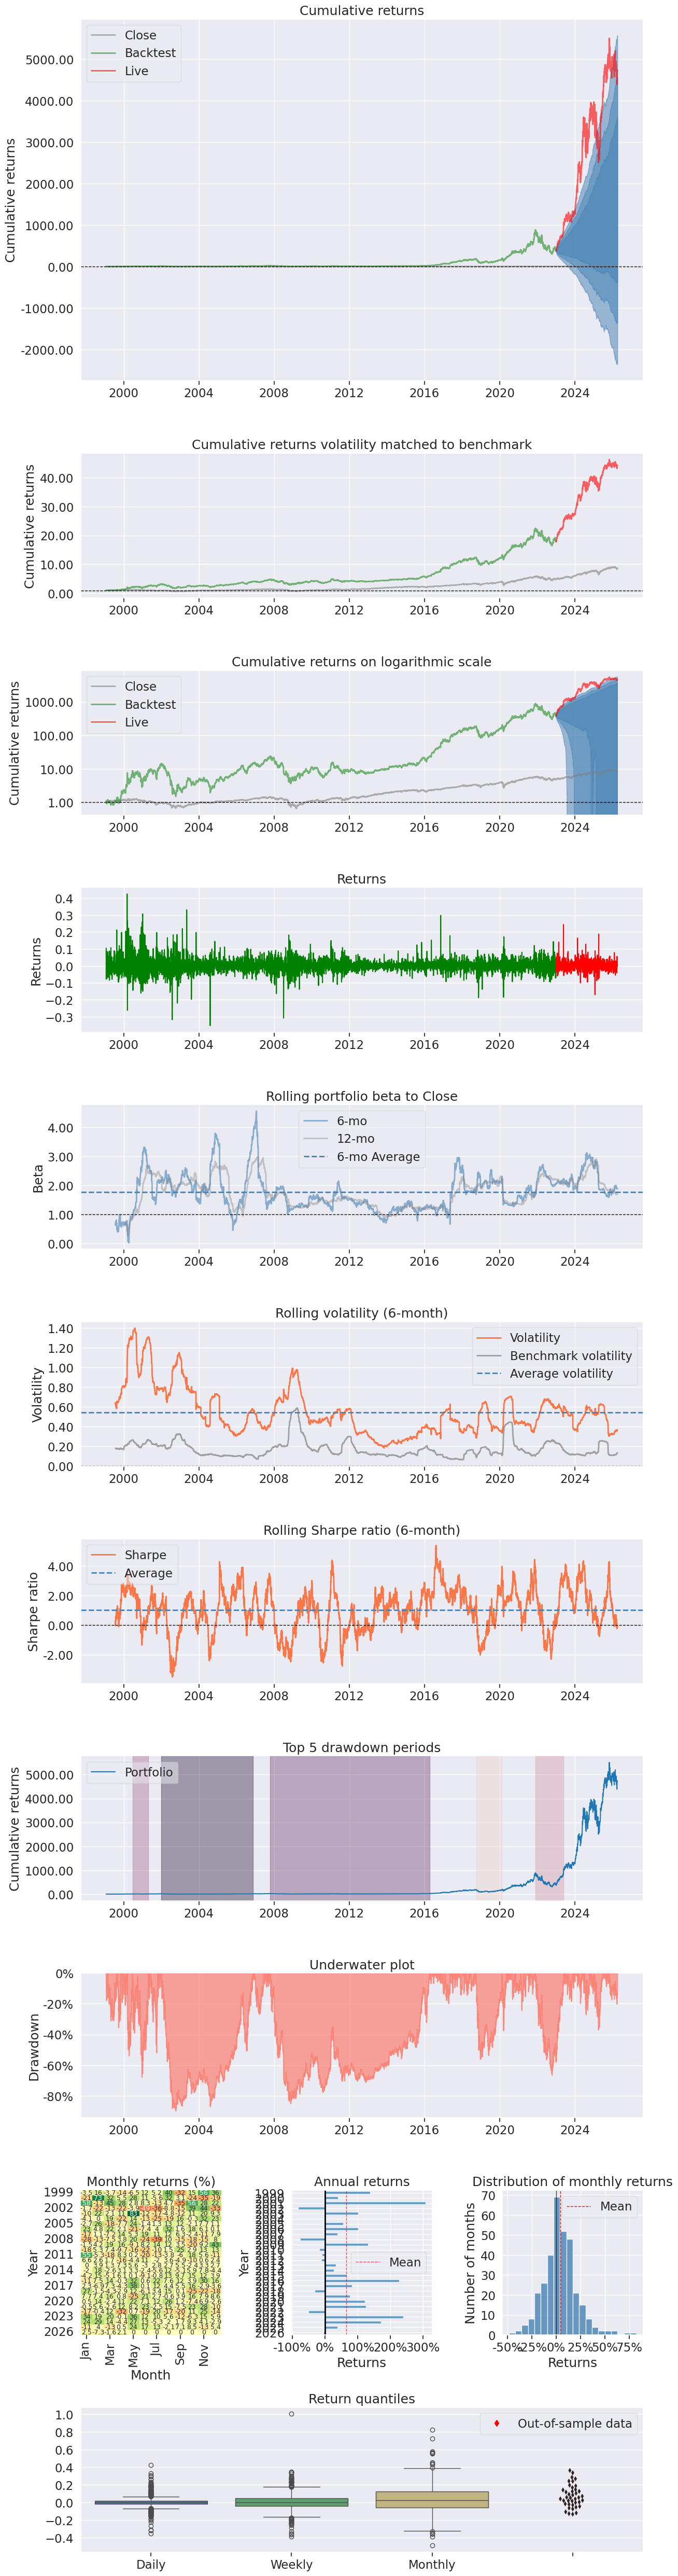

In [38]:
pf.create_returns_tear_sheet(returns, live_start_date='2023-01-01', benchmark_rets=bench_returns)